# Lighting peak-demand baseline

> **Before running:** run [`../data-cleaning/main.ipynb`](../data-cleaning/main.ipynb) from the `data-cleaning` folder first. This notebook requires all 14 cleaned floor/year CSVs in `data-cleaning/outputs/clean/`. It deliberately does not read the raw `data/` files or fall back to precomputed analytics.

This baseline addresses the proposal question: **How much can peak electricity demand be reduced in each zone without compromising lighting comfort?** It quantifies observed demand and lighting contributions, calibrates a transparent high-demand trigger, and checks measured ambient lux against illustrative targets. It does **not** claim a comfort-safe reduction: task-plane lux, fixture response, control measurements, and a credible control counterfactual are not available in the supplied telemetry.

## Method and assumptions

1. Read the cleaned minute-level files and derive per-zone total power (all recorded AC, lighting, and plug meters), lighting power, and available ambient lux.
2. Resample to 15-minute means. Keep an interval only when at least 80% of its 15 minute readings are present for that measure.
3. Use weekdays 08:00–17:45 as an **assumed** operating window, not measured occupancy. The proposal's calibration period is 6–31 March 2019; April 2019 is the evaluation period.
4. For each zone, use the March 95th percentile of valid total demand as a descriptive trigger, then count April intervals above it. Report the April maximum, lighting at that same interval, lux, and coverage.
5. Compare available April lux readings against 100, 150, 200, 300, and the proposal's illustrative 500 lux. Ambient sensor readings are not a substitute for occupied task-plane measurements.

Weekday holidays/closures are not removed because the cleaned source files do not carry the cleaning notebook's derived day labels. Treat the assumed schedule and resulting baselines accordingly. Results are descriptive, not causal estimates of achievable savings.

In [1]:
from pathlib import Path
import sys

candidates = [Path.cwd(), *Path.cwd().parents]
repo_root = next(
    (path for path in candidates if (path / "data-cleaning").is_dir() and (path / "baseline").is_dir()),
    None,
)
if repo_root is None:
    raise FileNotFoundError(
        "Could not locate the repository. Open this notebook from the project "
        "folder, or set the notebook working directory to the repository root."
    )

baseline_dir = repo_root / "baseline"
sys.path.insert(0, str(baseline_dir))
from _shared import clean_data_directory

clean_dir = clean_data_directory()
print(f"Using cleaned inputs from: {clean_dir}")

Using cleaned inputs from: C:\wamp64\www\IS4001 Sustainable Building Analytics\SBA-Final-Project\data-cleaning\outputs\clean


## Baseline tables and peak profile

The first table covers every zone with power data. The Floor 2 table isolates the proposal's deep-dive floor. Trigger exceedances are counts of 15-minute intervals, not independent peak events. A low coverage value should be treated as insufficient evidence rather than as low demand.

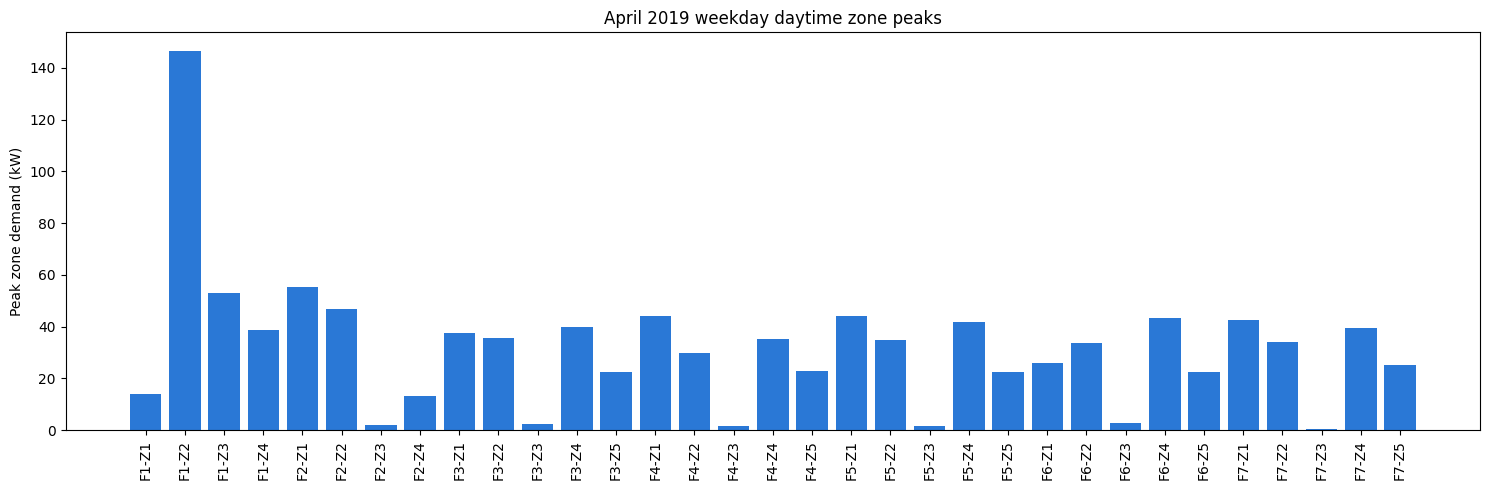

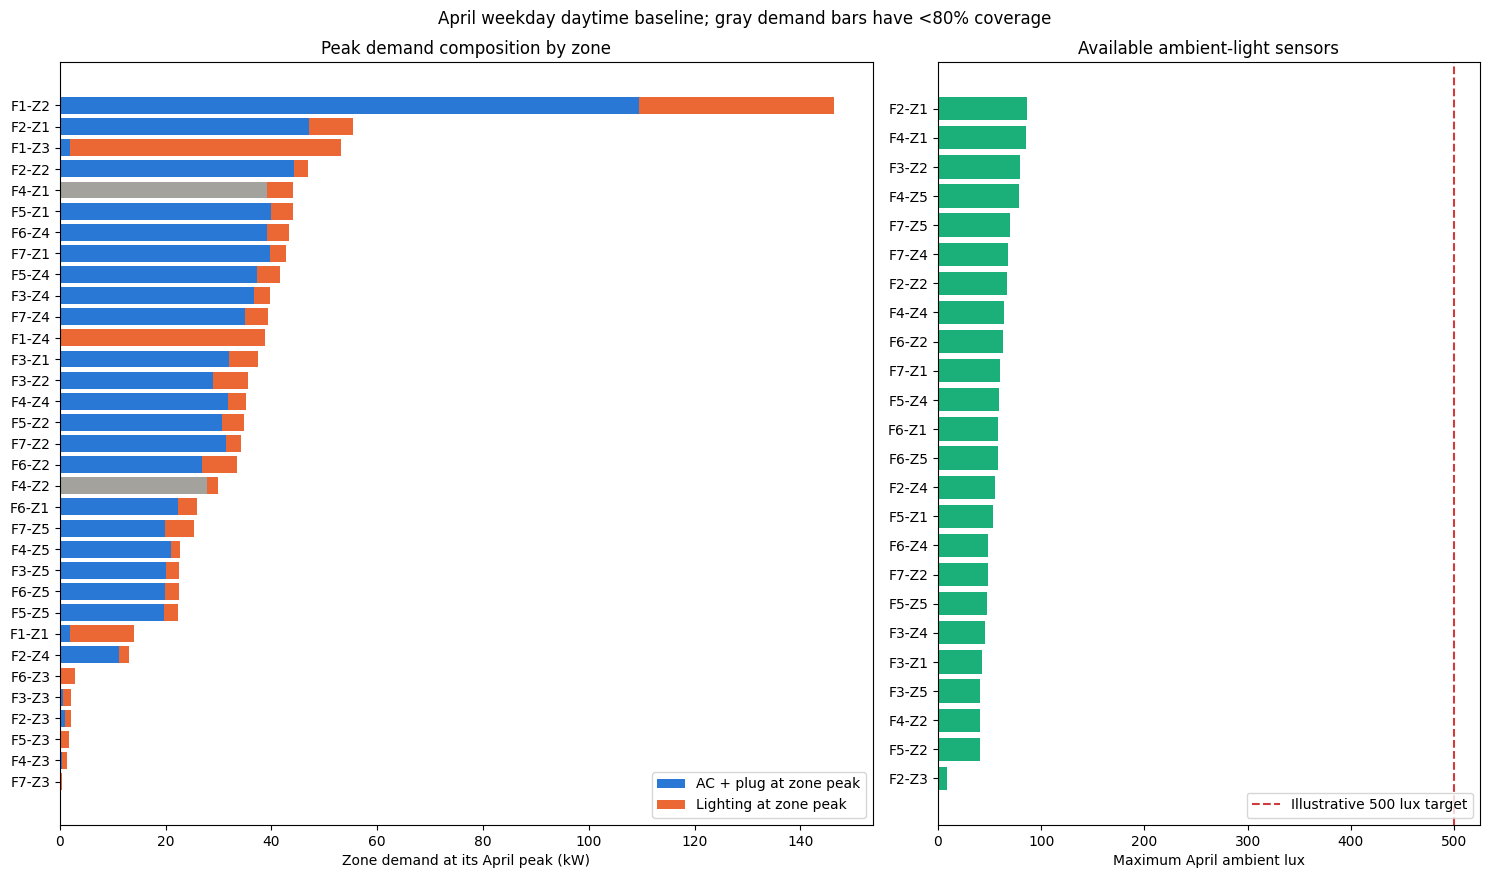

,floor,zone,march_calibration_intervals,march_valid_intervals,march_coverage_pct,march_p95_trigger_kW,april_evaluation_intervals,april_valid_intervals,april_coverage_pct,april_peak_time,april_peak_total_kW,lighting_kW_at_peak,lighting_share_at_peak_pct,ambient_lux_at_peak,april_max_ambient_lux,april_valid_lux_intervals,april_lux_coverage_pct,april_intervals_above_march_p95
0,1,1,720,720,100.000000,4.942700,880,880,100.000000,2019-04-22 17:45:00,14.014667,12.132000,86.566454,NaN,NaN,0,0.000000,25
1,1,2,720,720,100.000000,72.810967,880,880,100.000000,2019-04-29 14:45:00,146.400000,36.981333,25.260474,NaN,NaN,0,0.000000,213
2,1,3,720,720,100.000000,33.368800,880,880,100.000000,2019-04-30 17:30:00,53.058667,51.117333,96.341157,NaN,NaN,0,0.000000,26
3,1,4,720,720,100.000000,0.194067,880,880,100.000000,2019-04-09 17:45:00,38.780667,38.780667,100.000000,NaN,NaN,0,0.000000,38
4,2,1,720,720,100.000000,51.725600,880,877,99.659091,2019-04-17 15:45:00,55.470000,8.414667,15.169761,77.466667,86.400000,876,99.545455,198
5,2,2,720,720,100.000000,39.710400,880,877,99.659091,2019-04-22 09:45:00,46.938000,2.650000,5.645745,50.733333,67.266667,869,98.750000,179
6,2,3,720,720,100.000000,1.638800,880,880,100.000000,2019-04-29 11:15:00,2.097333,1.097333,52.320407,4.066667,8.466667,866,98.409091,48
7,2,4,720,720,100.000000,12.532733,880,877,99.659091,2019-04-22 13:30:00,13.095333,1.850000,14.127170,47.666667,55.266667,866,98.409091,466
8,3,1,720,528,73.333333,35.532033,880,761,86.477273,2019-04-19 13:30:00,37.456000,5.440667,14.525488,32.333333,42.733333,871,98.977273,276
9,3,2,720,528,73.333333,31.148167,880,761,86.477273,2019-04-19 13:15:00,35.478667,6.449333,18.178060,74.400000,79.666667,650,73.863636,252


,floor,zone,march_calibration_intervals,march_valid_intervals,march_coverage_pct,march_p95_trigger_kW,april_evaluation_intervals,april_valid_intervals,april_coverage_pct,april_peak_time,april_peak_total_kW,lighting_kW_at_peak,lighting_share_at_peak_pct,ambient_lux_at_peak,april_max_ambient_lux,april_valid_lux_intervals,april_lux_coverage_pct,april_intervals_above_march_p95
4,2,1,720,720,100.0,51.725600,880,877,99.659091,2019-04-17 15:45:00,55.470000,8.414667,15.169761,77.466667,86.400000,876,99.545455,198
5,2,2,720,720,100.0,39.710400,880,877,99.659091,2019-04-22 09:45:00,46.938000,2.650000,5.645745,50.733333,67.266667,869,98.750000,179
6,2,3,720,720,100.0,1.638800,880,880,100.000000,2019-04-29 11:15:00,2.097333,1.097333,52.320407,4.066667,8.466667,866,98.409091,48
7,2,4,720,720,100.0,12.532733,880,877,99.659091,2019-04-22 13:30:00,13.095333,1.850000,14.127170,47.666667,55.266667,866,98.409091,466


,floor,zone,illustrative_lux_target,valid_lux_intervals,intervals_at_or_above_target,share_at_or_above_target_pct
0,1,1,100,0,0,NaN
1,1,1,150,0,0,NaN
2,1,1,200,0,0,NaN
3,1,1,300,0,0,NaN
4,1,1,500,0,0,NaN
...,...,...,...,...,...,...
160,7,5,100,854,0,0.0
161,7,5,150,854,0,0.0
162,7,5,200,854,0,0.0
163,7,5,300,854,0,0.0


Tables and chart saved under: C:\wamp64\www\IS4001 Sustainable Building Analytics\SBA-Final-Project\baseline\outputs


In [2]:
from IPython.display import display
from lighting_peak_baseline import run_lighting_baseline

results = run_lighting_baseline()
display(results["zone_summary"])
display(results["floor2_deep_dive"])
display(results["lux_sensitivity"])
print(f"Tables and chart saved under: {results['output_directory']}")

## Baseline summary

The following summary uses April weekday daytime zone peaks and clearly separates coverage-qualified evidence from low-coverage zones. The lighting fraction describes the observed zone's load at its own peak, not a simultaneous building peak or an achievable reduction.

A 500-lux target is illustrative and exceeds the range of supplied ambient-light measurements. These data cannot establish that dimming would preserve comfort, so no scenario reduction is claimed. Validate sensor placement and task-plane requirements, fixture response, and matched control/treatment measurements before a dimming trial.

In [3]:
import pandas as pd

zone_summary = results["zone_summary"]
coverage_qualified = zone_summary.loc[zone_summary["april_coverage_pct"] >= 80]
with_demand = coverage_qualified.dropna(subset=["april_peak_total_kW"])
with_lux = zone_summary.loc[zone_summary["april_valid_lux_intervals"] > 0]
peak_zone = with_demand.loc[with_demand["april_peak_total_kW"].idxmax()]
lux_zone = with_lux.loc[with_lux["april_max_ambient_lux"].idxmax()]
floor2 = results["floor2_deep_dive"]
floor2_peak = floor2.loc[floor2["april_peak_total_kW"].idxmax()]

lighting_summary = pd.DataFrame([
    {"Baseline measure": "Zones with April demand coverage >=80%", "Value": f"{len(with_demand)} / {len(zone_summary)}"},
    {"Baseline measure": "Zones with March calibration coverage >=80%", "Value": f"{(zone_summary['march_coverage_pct'] >= 80).sum()} / {len(zone_summary)}"},
    {"Baseline measure": "Median April zone peak (coverage-qualified)", "Value": f"{with_demand['april_peak_total_kW'].median():.2f} kW"},
    {"Baseline measure": "Largest April zone peak (coverage-qualified)", "Value": f"F{int(peak_zone['floor'])}-Z{int(peak_zone['zone'])}: {peak_zone['april_peak_total_kW']:.2f} kW"},
    {"Baseline measure": "Median lighting share at each zone's peak", "Value": f"{with_demand['lighting_share_at_peak_pct'].median():.1f}%"},
    {"Baseline measure": "Zones with usable April lux readings", "Value": f"{len(with_lux)} / {len(zone_summary)}"},
    {"Baseline measure": "Maximum April ambient lux", "Value": f"F{int(lux_zone['floor'])}-Z{int(lux_zone['zone'])}: {lux_zone['april_max_ambient_lux']:.1f} lux"},
    {"Baseline measure": "Zones reaching illustrative 500 lux", "Value": f"{(with_lux['april_max_ambient_lux'] >= 500).sum()} / {len(with_lux)}"},
    {"Baseline measure": "Largest Floor 2 zone peak", "Value": f"F2-Z{int(floor2_peak['zone'])}: {floor2_peak['april_peak_total_kW']:.2f} kW"},
    {"Baseline measure": "Comfort-safe reduction estimate", "Value": "Not estimable from available data"},
])
display(floor2[["zone", "april_peak_total_kW", "lighting_kW_at_peak", "lighting_share_at_peak_pct", "ambient_lux_at_peak", "april_coverage_pct", "april_lux_coverage_pct"]].round(2))
display(lighting_summary)

,zone,april_peak_total_kW,lighting_kW_at_peak,lighting_share_at_peak_pct,ambient_lux_at_peak,april_coverage_pct,april_lux_coverage_pct
4,1,55.47,8.41,15.17,77.47,99.66,99.55
5,2,46.94,2.65,5.65,50.73,99.66,98.75
6,3,2.10,1.10,52.32,4.07,100.00,98.41
7,4,13.10,1.85,14.13,47.67,99.66,98.41


,Baseline measure,Value
0,Zones with April demand coverage >=80%,31 / 33
1,Zones with March calibration coverage >=80%,28 / 33
2,Median April zone peak (coverage-qualified),34.17 kW
3,Largest April zone peak (coverage-qualified),F1-Z2: 146.40 kW
4,Median lighting share at each zone's peak,14.1%
5,Zones with usable April lux readings,24 / 33
6,Maximum April ambient lux,F2-Z1: 86.4 lux
7,Zones reaching illustrative 500 lux,0 / 24
8,Largest Floor 2 zone peak,F2-Z1: 55.47 kW
9,Comfort-safe reduction estimate,Not estimable from available data
